# Derive and test 1D analytical solutions to simplified EGBE equations

Greg Tucker, CU Boulder, July 2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from egbelem import EgbeLem

## 1. Derive the analytical solutions

### General considerations for 1d

Let $x$ be distance from the head of the profile, and $\Delta x$ the width of the domain (one grid cell).

Drainage area: $A = x \Delta x$

Discharge: $Q = rA = rx\Delta x$

Rock erosion rate at steady state: $U = E_p + E_a$ (assumes no weathering)

#### Sediment flux

If we assume that bedrock abrasion is zero, then the rate of input of coarse sediment per unit channel length is $U\gamma \Delta x$, and the rate of output is $\beta Q_s$. This means,
$$
\frac{dQ_s}{dx} = U\gamma \Delta x - \beta Q_s
$$
Let $v = U\gamma \Delta x - \beta Q_s$. Then $dv = -\beta dQ_s$, and $dQs = -(1/\beta) dv$. Substitute:
$$
-\frac{1}{\beta} \frac{dv}{dx} = v
$$
$$
\frac{dv}{dx} = -\beta v
$$
Integrate:
$$
\int \frac{dv}{v} = -\int \beta dx
$$
$$
\ln v = -\beta x + C
$$
$$
v = e^{-\beta x}e^C
$$
Back-substitute:
$$
U\gamma \Delta x - \beta Q_s = e^{-\beta x}e^C
$$
When $x=0$, $Q_s = 0$, so
$$
e^C = U\gamma \Delta x
$$
And so,
$$
\boxed{Q_s = \frac{U\gamma \Delta x}{\beta} (1 - e^{-\beta x})}
$$
(Units verified. When $x$ is large, $Q_s \rightarrow \frac{U\gamma \Delta x}{\beta}$. More sediment with faster uplift $U$, greater fraction $\gamma$, or wider valley $\Delta x$, as expected. Less sediment with more rapid downstream attrition, $\beta$.)

#### Transport and plucking laws

The transport law is
$$
Q_s = I w k_t (\tau - \tau_c)^{3/2} (1 - \phi)
$$
where $k_t = M / \left(\rho^{1/2}(\sigma - \rho) g\right)$. Convert stress$^{3/2}$ $[M^{3/2}/(L^{3/2}T^3)]$ into $[L^2/T]$.

The plucking law is
$$
E_p = I k_p (\tau - \tau_c)^{3/2} (w / \Delta x) \phi
$$

The bedrock abrasion law is
$$
E_a = I \beta_r Q_s / \Delta x \phi
$$

### Case of fixed width

The width is
$$
w = k_w Q^{1/2}
$$

The shear stress is
$$
\tau = \rho g h S
$$
From Manning, $Q = (w/n) h^{5/3} S^{1/2}$, so $h^{5/3} = Qn / w S^{1/2}$, and $h = (Qn/wS^{1/2})^{3/5}$. So,
$$
\tau = \rho g n^{3/5} (Q/w)^{3/5} S^{7/10}
$$
and with the width rule,
$$
\tau = \rho g n^{3/5} k_w^{-3/5} Q^{3/10} S^{7/10}
$$

The transport law becomes
$$
Q_s = I w k_t (\rho g n^{3/5} k_w^{-3/5} r^{3/10} x^{3/10} \Delta x^{3/10} S^{7/10} - \tau_c)^{3/2} (1 - \phi)
$$



So, we can solve for $\phi(x)$ from this and the equilibrium transport rate by equating equilibrium sediment flux with this transport rate:
$$
I w k_t (\tau - \tau_c)^{3/2} (1 - \phi) = \frac{U\gamma \Delta x}{\beta} (1 - e^{-\beta x})
$$
Then,
$$
(1 - \phi) = \frac{U\gamma \Delta x}{\beta I w k_t (\tau - \tau_c)^{3/2}} (1 - e^{-\beta x})
$$
Or,
$$
\phi = 1 - \frac{U\gamma \Delta x}{\beta I w k_t (\tau - \tau_c)^{3/2}} (1 - e^{-\beta x})
$$
With the proviso that $\tau - \tau_c$ must always be $\ge 0$.

The slope-discharge (= slope-distance) relation should look something like the following.

Given no bedrock abrasion, the plucking rate should equal the uplift rate:
$$
I k_p (\tau - \tau_{cr})^{3/2} \phi w / \Delta x = U
$$
Which implies
$$
\phi = \frac{U \Delta x}{I k_p w (\tau - \tau_{cr})^{3/2}}
$$
Substituting the definition of $\phi$:
$$
1 - \frac{U\gamma \Delta x}{\beta I w k_t (\tau - \tau_{cr})^{3/2}} (1 - e^{-\beta x}) = \frac{U \Delta x}{I k_p w (\tau - \tau_{cr})^{3/2}}
$$
Multiply through...
$$
\beta I w k_t (\tau - \tau_{cr})^{3/2} - U\gamma \Delta x (1 - e^{-\beta x}) = \frac{U \Delta x \beta I w k_t (\tau - \tau_c)^{3/2}}{I k_p w (\tau - \tau_{cr})^{3/2}}
$$
Cancel and rearrange...
$$
\beta I w k_t (\tau - \tau_{cr})^{3/2} - U\gamma \Delta x (1 - e^{-\beta x}) = \frac{U \Delta x \beta k_t}{k_p}
$$
$$
\beta I w k_t (\tau - \tau_{cr})^{3/2} = \frac{U \Delta x \beta k_t}{k_p} + U\gamma \Delta x (1 - e^{-\beta x})
$$
$$
 (\tau - \tau_{cr})^{3/2} = \frac{U \Delta x }{k_p I w} + \frac{U\gamma \Delta x (1 - e^{-\beta x})}{\beta I w k_t}
$$
The predicted steady shear stress is:
$$
\boxed{\tau = \left( \frac{U \Delta x }{k_p I w} + \frac{U\gamma \Delta x (1 - e^{-\beta x})}{\beta I w k_t} \right)^{2/3} + \tau_{cr}}
$$
Definition of $\tau$,
$$
\rho g n^{3/5} (Q/w)^{3/5} S^{7/10} = \left( \frac{U \Delta x }{k_p I w} + \frac{U\gamma \Delta x (1 - e^{-\beta x})}{\beta I w k_t} \right)^{2/3} + \tau_{cr}
$$
And finally, solving for $S$:
$$
\boxed{
S = \left[ \frac{\left( \frac{U \Delta x }{k_p I w} + \frac{U\gamma \Delta x (1 - e^{-\beta x})}{\beta I w k_t} \right)^{2/3} + \tau_{cr}}{\rho g n^{3/5} (Q/w)^{3/5}} \right]^{10/7}
}
$$
This can be viewed as having three terms: one representing the slope needed to overcome the transport threshold, one representing transport, and one representing bedrock erosion (plucking).


### Case of near-threshold width

#### Width relation

Shear stress is
$$
\tau = (1 + \epsilon ) \tau_c
$$
By mass conservation, discharge is cross-section averaged velocity, $u$, times cross-sectional area. In a rectangular channel, as is assumed here, area is width times depth: $Q = uwh$, or $w = Q / uh$. Velocity is calculated from the Manning equation, so that
$$
w = \frac{Qn}{h^{5/3} S^{1/2}}
$$
Depth can be obtained from shear stress for steady, uniform, wide-channel flow:
$$
\rho g h S = (1 + \epsilon ) \tau_c
$$
or
$$
h = \frac{(1 + \epsilon ) \tau_c}{\rho g S}
$$
Substituting,
$$
w = \frac{Qn}{(\frac{(1 + \epsilon ) \tau_c}{\rho g S})^{5/3} S^{1/2}}
$$
$$
w = \frac{Qn\rho^{5/3} g^{5/3} S^{5/3}}{((1 + \epsilon ) \tau_c)^{5/3} S^{1/2}}
$$
$$
w = \frac{n\rho^{5/3} g^{5/3} QS^{7/6}}{(1 + \epsilon )^{5/3} \tau_c^{5/3}}
$$
Plugging in for the definition of $\tau_c$,
$$
\boxed{w = \frac{nQS^{7/6}}{(1 + \epsilon )^{5/3} \theta_c^{5/3} R^{5/3} D^{5/3}}}
$$
where $R = (\sigma - \rho) / \rho$. 

If we were to use the Wickert-Schildgen grain roughness approach, then
$$
n = 0.17 D^{1/6} / g^{1/2}
$$
and in that case, width would be slightly different:
$$
w = 0.17 \frac{QS^{7/6}}{g^{1/2} (1 + \epsilon )^{5/3} \theta_c^{5/3} R^{5/3} D^{3/2}}
$$

#### Alluvial cover and bedrock exposure

Given no bedrock abrasion, the plucking rate should equal the uplift rate:
$$
I k_p (\tau - \tau_{cr})^{3/2} \phi w / \Delta x = U
$$
Using the near-threshold principle,
$$
\phi = \frac{U \Delta x}{I k_p \epsilon^{3/2} \tau_{cr}^{3/2} w}
$$
Substituting for width:
$$
\boxed{\phi = \frac{U(1 + \epsilon)^{5/3} \theta_c^{5/3} R^{5/3} D^{5/3}}{I k_p \epsilon^{3/2} \tau_{cr}^{3/2} nrx S^{7/6}}}
$$


#### Sediment flux

The sediment transport capacity is
$$
Q_s = w I k_t (\tau - \tau_c)^{3/2} (1 - \phi)
$$
When combined with the definition of width, and the fact that for near-threshold channels $\tau - \tau_c = \epsilon \tau_c$,
$$
Q_s = \frac{n I k_t \epsilon^{3/2} \tau_c^{3/2} Q S^{7/6} (1 - \phi)}{[(1+\epsilon) \theta_c R D]^{5/3}}
$$


The equilibrium sediment flux from above is
$$
Q_s = \frac{U\gamma \Delta x}{\beta} (1 - e^{-\beta x})
$$

These two should be equal at steady state.

#### Slope

Equating capacity and steady-state flux:
$$
\frac{n I k_t \epsilon^{3/2} \tau_c^{3/2} Q S^{7/6} (1 - \phi)}{[(1+\epsilon) \theta_c R D]^{5/3}} = \frac{U\gamma \Delta x}{\beta} (1 - e^{-\beta x})
$$
Solving for $S$:
$$
S^{7/6} (1 - \phi) = \frac{U\gamma \Delta x [(1+\epsilon) \theta_c R D]^{5/3} (1 - e^{-\beta x})}{\beta n I k_t \epsilon^{3/2} \tau_c^{3/2} Q } 
$$
Plugging in for $\phi$:
$$
S^{7/6} \left(1 - \frac{U(1 + \epsilon)^{5/3} \theta_c^{5/3} R^{5/3} D^{5/3}}{I k_p \epsilon^{3/2} \tau_{cr}^{3/2} nrx S^{7/6}} \right) = \frac{U\gamma \Delta x [(1+\epsilon) \theta_c R D]^{5/3} (1 - e^{-\beta x})}{\beta n I k_t \epsilon^{3/2} \tau_c^{3/2} Q } 
$$
then:
$$
\boxed{S = \left( \frac{U \left[ (1 + \epsilon) \theta_c R D\right]^{5/3}}{I n \epsilon^{3/2} \tau_c^{3/2}rx} 
\left[ \frac{\gamma (1 - e^{-\beta x})}{\beta k_t} + \frac{1}{k_p} \right] \right)^{6/7}}
$$


Here the two terms in brackets represent transport and bedrock erosion (plucking), respectively.


## 2. Test the analytical solutions

### Functions

In [2]:
def sed_flux_analytic_ss1(x, U, gam, dx, beta):
    return (U * gam * dx / beta) * (1.0 - np.exp(-beta * x))

def expected_shear_stress(x, S, rho, n, kw, rs, ry, dx, g=9.81):
    w = kw * (ry * dx * x)**0.5
    Q = x * dx * rs
    return rho * g * n**0.6 * (Q / w)**0.6 * S**0.7

def calc_kq(rho=1000., rhos=2650., g=9.81, M=3.97):
    """
    Calculate and return value of transport coefficient kq given
    water and sediment density (rho and rhos), gravitational 
    acceleration (g), and the modified Meyer-Peter Muller coefficient.
    """
    kqs = M / (rho**0.5 * (rhos - rho) * g) # units of seconds
    kqy = kqs * 365.25 * 24 * 3600.  # include conversion transport rate to m2/y
    return kqs, kqy

def plot_profile(model, thing_to_plot="topographic__elevation", yaxis_label="Elevation (m)"):
    grid = model.grid
    nc = grid.number_of_node_columns
    midrow = np.arange(nc + 1, 2 * nc, dtype=int)
    x = grid.x_of_node[midrow]
    if isinstance(thing_to_plot, str):
        z = grid.at_node[thing_to_plot][midrow]
    else:
        z = thing_to_plot[midrow]
    plt.plot(x / 1000., z, '.-')
    plt.xlabel("Distance (km)")
    plt.ylabel(yaxis_label)
    return x, midrow, z

def slope_fw(x, beta, D, dx, gamma, I, kp, kqy, kw, mann, ry, U, thetac=0.05, sig=2650., rho=1000., g=9.81):
    """Calculate and return analytical solution for slope for fixed width option in 1d."""
    spy = 365.25 * 24 * 3600.
    Q = ry * x * dx
    w = kw * Q**0.5
    denom = rho * g * mann**0.6 *((Q[:-1] / spy) / w[:-1])**0.6
    t1 = U * dx / (kp * I * w[:-1]) 
    t2 = U * gamma * dx * (1.0 - np.exp(-beta * x[:-1])) / (beta * I * w[:-1] * kqy)
    tauc = thetac * (sig - rho) * g * D
    tau = (t1 + t2)**(2. / 3.) + tauc
    Sprd = (tau / denom)**(10. / 7.)
    return Sprd

def slope_nt(x, beta, D, gamma, I, ry, U, eps=0.2, thetac=0.05, sig=2650., rho=1000., g=9.81):
    """Calculate and return analytical solution for slope for near-threshold width option in 1d."""
    spy = 365.25 * 24 * 3600.
    outern = U * ((1 + eps) * thetac * R * D)**(5. / 3.) * spy
    tauc = thetac * (sig - rho) * g * D
    outerd = I * mann * (eps * tauc)**1.5 * ry * x
    num = gamma * (1.0 - np.exp(-beta * x))
    denom = beta * kqy
    Sprd = ((outern / outerd) * (num / denom + 1.0 / kp))**(6. / 7.)
    return Sprd

In [3]:
# Get transport coefficients in time units of seconds (kqs) and years (kqy)
kqs, kqy = calc_kq()
print(kqs, kqy)

7.755995620343166e-06 244.76060738854153


In [4]:
# Parameters
dx = 5000.0
xmax = 300000.0
beta = 1.0e-4
U = 5.0e-4
I = 0.01
r = 5.0
Kp = 1.0
gamma = 1.0

In [5]:
# Array of position (x) values for plotting
x = np.arange(dx, xmax + dx, dx)

## Model runs

Two runs are used for testing the analytical solutions: one using fixed width, and the other using near-threshold width.

### Fixed width

In [6]:
params = EgbeLem.DEFAULT_PARAMS
params

{'grid': {'source': 'create',
  'create_grid': {'RasterModelGrid': [(31, 31), {'xy_spacing': 1000.0}]}},
 'clock': {'start': 0.0, 'stop': 1000.0, 'step': 10.0},
 'output': {'plot_times': 250.0,
  'save_times': 1000.0,
  'report_times': 100.0,
  'save_path': 'egbe_run',
  'clobber': True,
  'fields': None,
  'plot_to_file': True},
 'initial_conditions': {'use_field_for_initial_topo': False,
  'initial_topo': 0.0,
  'random_topo_amp': 10.0,
  'use_field_for_initial_sed_classes': False,
  'init_grains_weight': array([17331.])},
 'baselevel': {'uplift_rate': 0.0001},
 'flow_routing': {'flow_metric': 'D8',
  'update_flow_depressions': True,
  'depression_handler': 'fill',
  'epsilon': True,
  'bankfull_runoff_rate': 1.0},
 'fluvial': {'intermittency_factor': 0.01,
  'sediment_porosity': 0.3333333333333333,
  'depth_decay_scale': 1.0,
  'plucking_coefficient': 0.0001,
  'epsilon': 0.2,
  'abrasion_coefficients': [0.0001],
  'bedrock_abrasion_coefficient': 0.0001,
  'fractions_from_plucking':

In [7]:
g = 9.81
D = 0.015
thetac = 0.05
sig = 2650.
rho = 1000.
taucr = thetac * (sig - rho) * g * D  # set rock threshold the same as sediment

params["grid"]["create_grid"]["RasterModelGrid"] = [
    (3, 62),
    {'xy_spacing': 5000.0},
    {'boundary_conditions' :
        {
            'set_closed_boundaries_at_grid_edges': [False, True, True, True]
        }
    }
]
params["clock"] = {"start": 0.0, "stop": 2.0e7, "step": 1000}
params['output']['plot_times'] = 2.0e8
params['output']['save_times'] = 2.0e7
params['output']['report_times'] = 2.5e6
params['output']['plot_to_file'] = False
params['output']['save_path'] = 'egbelem-fw-sf'
params["baselevel"]["uplift_rate"] = 0.0005
params["flow_routing"]["bankfull_runoff_rate"] = 5.0
params["fluvial"]["grain_sizes"] = [D]
params["fluvial"]["sediment_porosity"] = 0.4
params["fluvial"]["plucking_coefficient"] = 1.0
params["fluvial"]["bedrock_abrasion_coefficient"] = 0.0 #0.0005
params["fluvial"]["abrasion_coefficients"] = [0.0001]
params["fluvial"]["tau_star_c_median"] = thetac
params["fluvial"]["fractions_from_plucking"] = [1.]
params["fluvial"]["plucking_by_tools_flag"] = False
params["fluvial"]["mannings_n"] = 0.05

In [8]:
modelsf = EgbeLem(params=params)

/Users/yuvalshmilovitz/Dropbox/Mac/Documents/git_folders/ys-sm-gt/gbe_extended/src/landlab/graph/sort/sort.py:724: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  angle_of_spoke_at_hub = np.arctan2(dy, dx, where=spokes_at_hub != -1)


In [9]:
modelsf.run()

EgbeLem time = 0.0
Base class placeholder for plot() at time 0.0
EgbeLem time = 2500000.0
EgbeLem time = 5000000.0
EgbeLem time = 7500000.0
EgbeLem time = 10000000.0
EgbeLem time = 12500000.0
EgbeLem time = 15000000.0
EgbeLem time = 17500000.0
EgbeLem time = 20000000.0


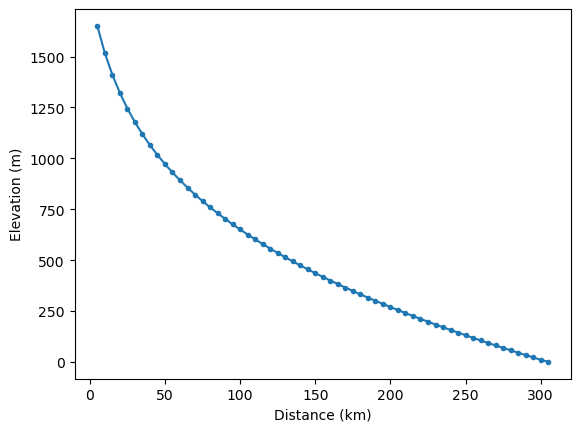

In [10]:
_ = plot_profile(modelsf)

In [11]:
# Translate parameters into symbols
M = 3.97
U = params["baselevel"]["uplift_rate"]
gam = params["fluvial"]["fractions_from_plucking"][0]
dx = modelsf.grid.dx
beta = params["fluvial"]["abrasion_coefficients"][0]
kp = params["fluvial"]["plucking_coefficient"]
kw = params["fluvial"]["fixed_width_coeff"]
rho = params["fluvial"]["rho_water"]
sig = params["fluvial"]["rho_sed"]
mann = params["fluvial"]["mannings_n"]
thetac = params["fluvial"]["tau_star_c_median"]
D = params["fluvial"]["grain_sizes"][0]
ry = params["flow_routing"]["bankfull_runoff_rate"]
rs = ry / (365.25 * 24 * 3600.)

#### Check very basic things that should be "built in"

**1. Discharge**

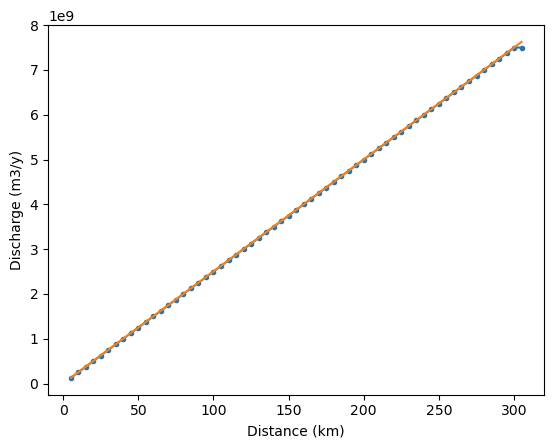

In [12]:
x, midrow, Qsim = plot_profile(modelsf, "surface_water__discharge", "Discharge (m3/y)")
Qprd = x * dx * ry
plt.plot(x / 1000., Qprd)

**2. Channel width**

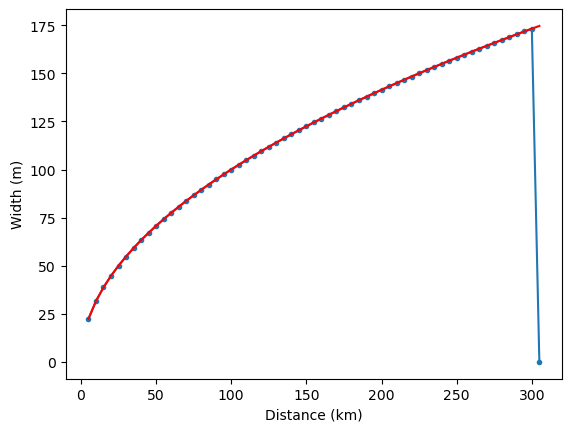

In [13]:
x, midrow, wsim = plot_profile(modelsf, modelsf.eroder._channel_width, "Width (m)")
wprd = kw * (x * dx * r)**0.5
_ = plt.plot(x / 1000., wprd, 'r')

#### Check "semi-analytic" solutions

These are solutions that require input of model-generated fields such as $S$, $\phi$, etc.

**1. Shear stress**

Check that $\tau = \rho g n^{0.6} (Q / w)^{0.6} S^{0.7}$

In [14]:
S = modelsf.grid.at_node["topographic__steepest_slope"][midrow]

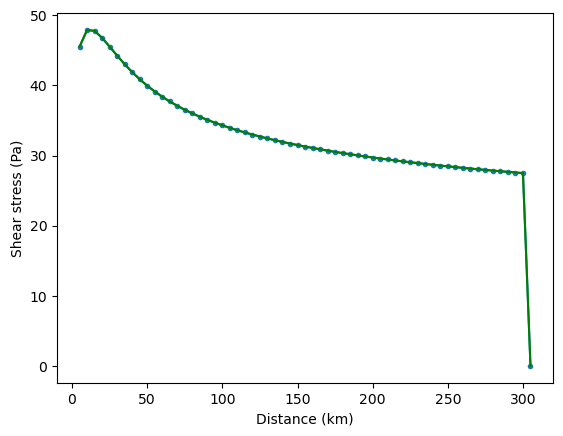

In [15]:
x, midrow, tausim = plot_profile(modelsf, modelsf.eroder._tau, "Shear stress (Pa)")
tauprd = expected_shear_stress(x, S, rho, mann, kw, rs, ry, dx)
_ = plt.plot(x / 1000., tauprd, 'g')

**3. Sediment flux**

Check that $Q_s = I w k_t (\tau - \tau_c)^{1.5} (1 - \phi)$

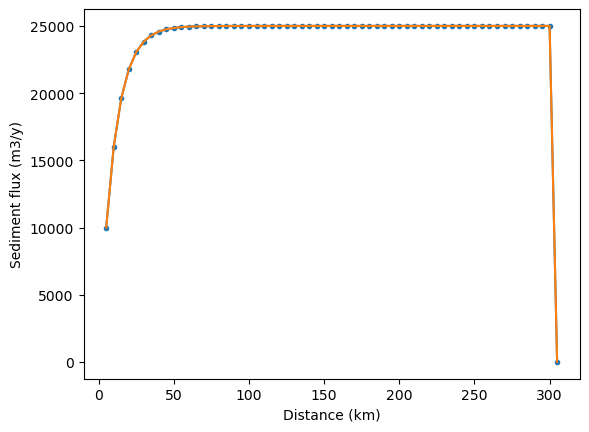

In [16]:
phisim = modelsf.grid.at_node["bedrock__exposure_fraction"][midrow]
taucprd = thetac * (sig - rho) * g * D
tauex = np.maximum(tausim - taucprd, 0.0)
Qsprd1 = I * wsim * kqy * tauex**1.5 * (1.0 - phisim)
_, _, Qssim = plot_profile(modelsf, "bedload_sediment__volume_outflux", "Sediment flux (m3/y)")
plt.plot(x / 1000., Qsprd1)

#### Check independent analytic solutions

**1. Sediment flux**

Check that $Q_s = \frac{U \gamma \Delta x}{\beta} \left(1 - \exp(-\beta x)\right)$.

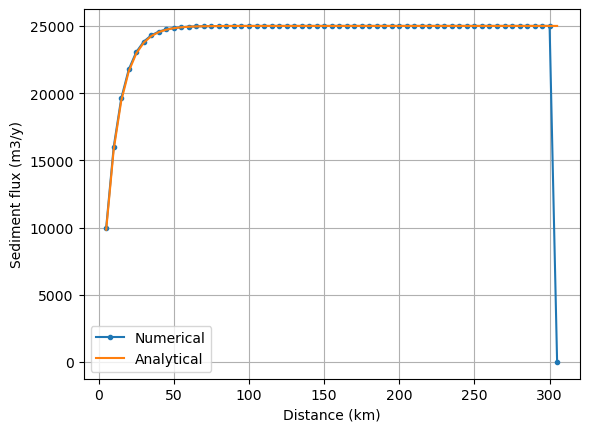

In [17]:
_ = plot_profile(modelsf, "bedload_sediment__volume_outflux", "Sediment flux (m3/y)")
Qsprd = sed_flux_analytic_ss1(x, U, gam, dx, beta)
plt.plot(x / 1000., Qsprd)
plt.grid(True)
_ = plt.legend(["Numerical", "Analytical"])

**2. Alluvial cover fraction**

Check that alluvial cover fraction is
$$
1 - \phi = \frac{Q_s}{Q_c}
$$
where $Q_c$ is transport capacity, defined as
$$
Q_c = I w k_t (\tau - \tau_c)^{3/2}
$$


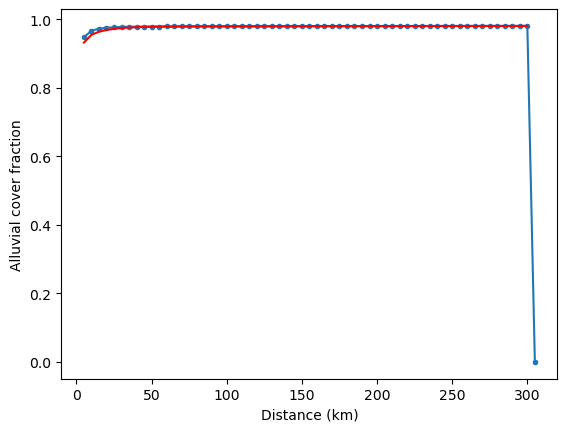

In [18]:
_, _, phisim = plot_profile(modelsf, 1.0 - modelsf.grid.at_node["bedrock__exposure_fraction"], "Alluvial cover fraction")
covsim = 1.0 - phisim
tauexprd = np.maximum(tauprd - taucprd, 0.0)
Qcprd = I * kqy * wprd * tauexprd**1.5
covprd = Qsprd[:-1] / Qcprd[:-1] #phi_analytic_fw(x, U, gam, dx, beta, I, kw, r, M, rho, sig, mann, S, thetac, D)
plt.plot(x[:-1] / 1000., covprd, 'r')

**3. Shear stress**

Check that
$$
\tau = \left( \frac{U \Delta x }{k_p I w} + \frac{U\gamma \Delta x (1 - e^{-\beta x})}{\beta I w k_t} \right)^{2/3} + \tau_{cr}
$$


Text(0, 0.5, 'Shear stress (Pa)')

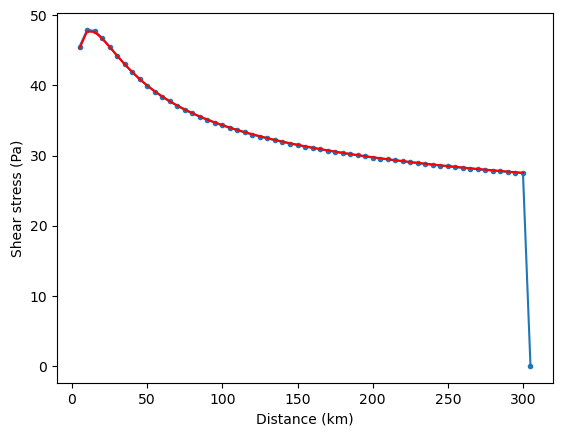

In [19]:
plt.plot(x / 1000., tausim, '.-')
t1 = U * dx / (kp * I * wsim[:-1]) 
t2 = U * gamma * dx * (1.0 - np.exp(-beta * x[:-1])) / (beta * I * wsim[:-1] * kqy)
tauprd = (t1 + t2)**(2. / 3.) + taucprd
plt.plot(x[:-1] / 1000., tauprd, 'r')
plt.xlabel("Distance (km)")
plt.ylabel("Shear stress (Pa)")

**4. Slope**

Check that
$$
\boxed{
S = \left[ \frac{\left( \frac{U \Delta x }{k_p I w} + \frac{U\gamma \Delta x (1 - e^{-\beta x})}{\beta I w k_t} \right)^{2/3} + \tau_{cr}}{\rho g n^{3/5} (Q/w)^{3/5}} \right]^{10/7}
}
$$


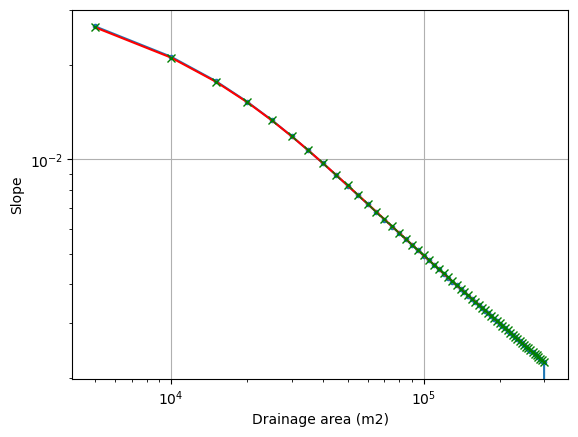

In [20]:
spy = 365.25 * 24 * 3600.
Ssim = modelsf.grid.at_node["topographic__steepest_slope"][midrow]
denom = rho * g * mann**0.6 *((Qprd[:-1] / spy) / wprd[:-1])**0.6
Sprd = (tauprd / denom)**(10. / 7.)
Sprdfn = slope_fw(x, beta, D, dx, gamma, I, kp, kqy, kw, mann, ry, U)
plt.loglog(x, Ssim, '.-')
plt.loglog(x[:-1], Sprd, 'r')
plt.loglog(x[:-1], Sprdfn, 'gx')
plt.xlabel("Drainage area (m2)")
plt.ylabel("Slope")
plt.grid(True)

**5. Profile**

Check that integrated slope matches the profile.

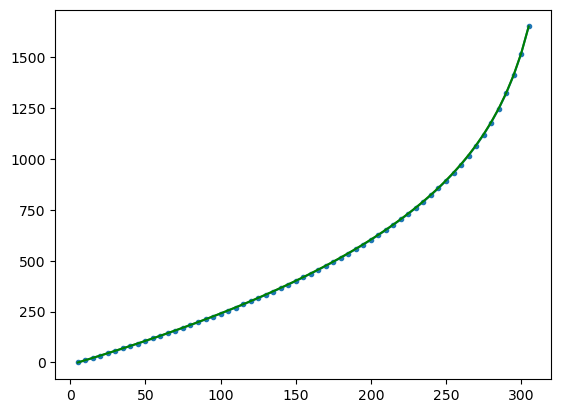

In [21]:
zsim = modelsf.grid.at_node["topographic__elevation"][midrow]
Sprdfn = slope_fw(x, beta, D, dx, gamma, I, kp, kqy, kw, mann, ry, U)
Sprdfnp = np.flip(Sprdfn)
zprd = np.zeros(len(x))
zprd[1:] = np.cumsum(Sprdfnp * dx)
plt.plot(x / 1000., np.flip(zsim), '.-')
plt.plot(x / 1000., zprd, 'g')

### Dynamic (near-threshold) width

In [73]:
D = 0.015
#mann = 0.05
mann = 0.17 * D**(1/6) / g**0.5
paramsnt = params.copy()
paramsnt["clock"]["stop"] = 5.0e7
paramsnt["fluvial"]["use_fixed_width"] = False
paramsnt["fluvial"]["mannings_n"] = mann
paramsnt["fluvial"]["grain_sizes"] = [D]
print("n is", paramsnt["fluvial"]["mannings_n"])
tauc = thetac * (sig - rho) * g * D
print("Implied bank threshold stress is", tauc, "Pa")
print("Implied channel shear stress is", 1.2 * tauc, "Pa")
paramsnt["fluvial"]["tau_c_bedrock"] = tauc
params['output']['save_path'] = 'egbelem-nt-sf'
params['output']['save_times'] = 5.0e7

n is 0.026954397428914405
Implied bank threshold stress is 12.139875 Pa
Implied channel shear stress is 14.56785 Pa


In [74]:
modelsfnt = EgbeLem(params=paramsnt)

In [75]:
modelsfnt.run()

EgbeLem time = 0.0
Base class placeholder for plot() at time 0.0
EgbeLem time = 2500000.0
EgbeLem time = 5000000.0
EgbeLem time = 7500000.0
EgbeLem time = 10000000.0
EgbeLem time = 12500000.0
EgbeLem time = 15000000.0
EgbeLem time = 17500000.0
EgbeLem time = 20000000.0
EgbeLem time = 22500000.0
EgbeLem time = 25000000.0
EgbeLem time = 27500000.0
EgbeLem time = 30000000.0
EgbeLem time = 32500000.0
EgbeLem time = 35000000.0
EgbeLem time = 37500000.0
EgbeLem time = 40000000.0
EgbeLem time = 42500000.0
EgbeLem time = 45000000.0
EgbeLem time = 47500000.0
EgbeLem time = 50000000.0


Text(0, 0.5, 'Elevation (m)')

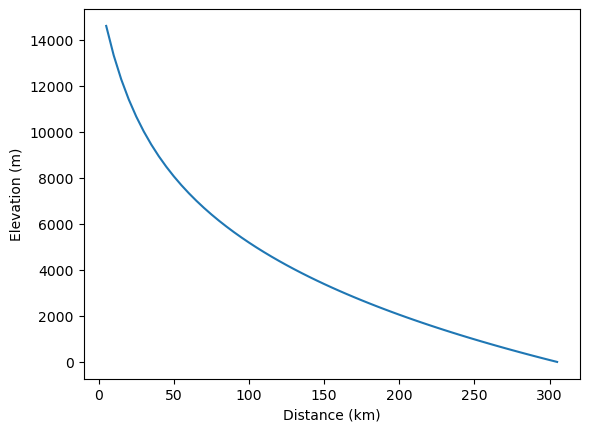

In [76]:
plt.plot(x / 1000., modelsfnt.grid.at_node["topographic__elevation"][midrow])
plt.xlabel("Distance (km)")
plt.ylabel("Elevation (m)")

#### Check "semi-analytic" solutions

**1. Width**

Check that
$$
\boxed{w = \frac{nQS^{7/6}}{(1 + \epsilon )^{5/3} \theta_c^{5/3} R^{5/3} D^{5/3}}}
$$



In [77]:
# Get additional parameters
eps = paramsnt["fluvial"]["epsilon"]
R = (sig - rho) / rho
thetac = paramsnt["fluvial"]["tau_star_c_median"]
D = paramsnt["fluvial"]["grain_sizes"][0]
taucr = paramsnt["fluvial"]["tau_c_bedrock"]
mann = paramsnt["fluvial"]["mannings_n"]
r = paramsnt["flow_routing"]["bankfull_runoff_rate"]
U = paramsnt["baselevel"]["uplift_rate"]
I = paramsnt["fluvial"]["intermittency_factor"]
kp = paramsnt["fluvial"]["plucking_coefficient"]

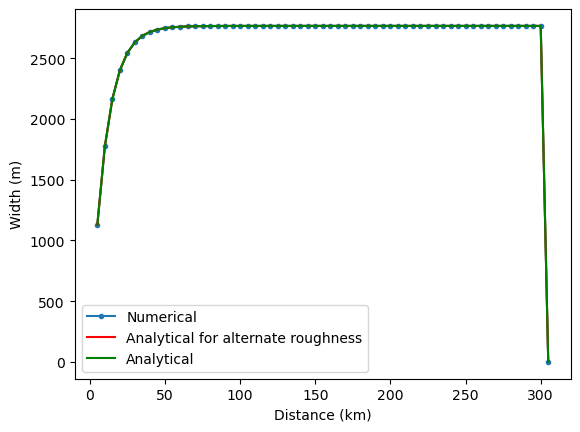

In [78]:
wsim = modelsfnt.eroder._channel_width[midrow]
qysim = modelsfnt.grid.at_node["surface_water__discharge"][midrow]
qssim = qysim / spy
Ssim = modelsfnt.grid.at_node["topographic__steepest_slope"][midrow]
plt.plot(x / 1000., wsim, '.-')
denom1 = g**0.5 * ((1.0 + eps) * thetac * R)**(5. / 3.) * D**1.5
wprd1 = 0.17 * qssim * Ssim**(7. / 6.) / denom1 # this is what it would be if we used Wickert's grain-based roughness
denom2 = ((1.0 + eps) * thetac * R * D)**(5. / 3.) / mann
wprd2 = qssim * Ssim**(7. / 6.) / denom2
plt.plot(x / 1000., wprd1, 'r')
plt.plot(x / 1000., wprd2, 'g')

plt.xlabel("Distance (km)")
plt.ylabel("Width (m)")
plt.legend(['Numerical', 'Analytical for alternate roughness', 'Analytical'])

**2. Shear stress**

Check that
$$
\tau = (1 + \epsilon) \tau_c
$$

(1 + eps) tauc = 14.56785


Text(0, 0.5, 'Shear stress (Pa)')

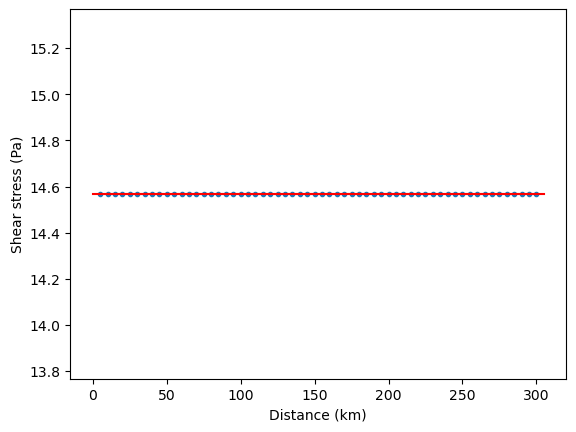

In [79]:
tausim = modelsfnt.eroder._tau[midrow]
plt.plot(x[:-1] / 1000., tausim[:-1], '.-')
tauprd = (1.0 + eps) * thetac * (sig - rho) * 9.81 * D
plt.plot([0, x[-1] / 1000.], [tauprd, tauprd], 'r')
print("(1 + eps) tauc =", tauprd)
plt.xlabel("Distance (km)")
plt.ylabel("Shear stress (Pa)")

**3. Bedrock exposure fraction**

Check that:
$$
\phi = \frac{U \Delta x}{I k_p (\tau - \tau_{cr})^{3/2} w}
$$



/var/folders/k2/skpg2jsd2ms7rfthlmp9nhg00000gn/T/ipykernel_13108/1759037793.py:4: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  phiprd1 = np.divide(U * dx, denom, where=(denom > 0.0))


Text(0, 0.5, 'Bedrock exposure fraction')

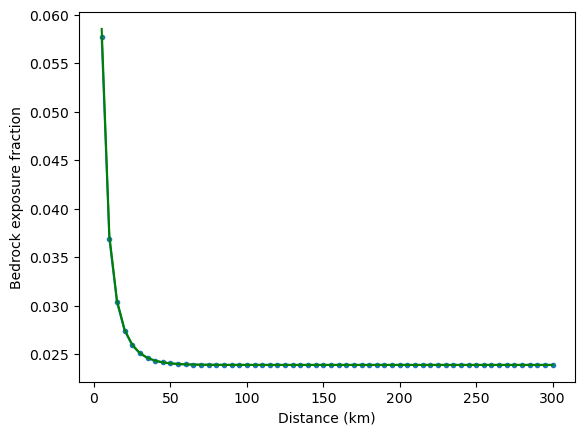

In [80]:
phisim = modelsfnt.grid.at_node["bedrock__exposure_fraction"][midrow]
plt.plot(x[:-1] / 1000., phisim[:-1], '.-')
denom = I * kp * np.maximum(tausim - taucr, 0.0)**1.5 * wsim
phiprd1 = np.divide(U * dx, denom, where=(denom > 0.0))
plt.plot(x[:-1] / 1000., phiprd1[:-1], 'g')
plt.xlabel("Distance (km)")
plt.ylabel("Bedrock exposure fraction")

Check that:
$$
\phi = \frac{U \Delta x}{I k_p \epsilon^{3/2} \tau_{cr}^{3/2} w}
$$


/var/folders/k2/skpg2jsd2ms7rfthlmp9nhg00000gn/T/ipykernel_13108/3650648258.py:3: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  phiprd2 = np.divide(U * dx, denom, where=(denom > 0.0))


Text(0, 0.5, 'Bedrock exposure fraction')

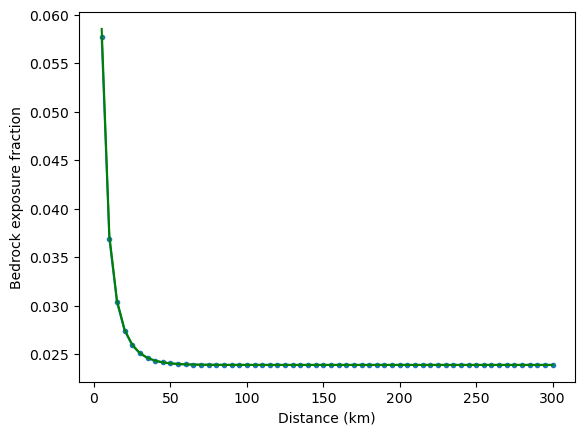

In [81]:
plt.plot(x[:-1] / 1000., phisim[:-1], '.-')
denom = I * kp * eps**1.5 * taucr**1.5 * wsim
phiprd2 = np.divide(U * dx, denom, where=(denom > 0.0))
plt.plot(x[:-1] / 1000., phiprd2[:-1], 'g')
plt.xlabel("Distance (km)")
plt.ylabel("Bedrock exposure fraction")

Check that:
$$
\boxed{\phi = \frac{U(1 + \epsilon)^{5/3} \theta_c^{5/3} R^{5/3} D^{5/3}}{I k_p \epsilon^{3/2} \tau_{cr}^{3/2} nrx S^{7/6}}}
$$

/var/folders/k2/skpg2jsd2ms7rfthlmp9nhg00000gn/T/ipykernel_13108/3471863994.py:4: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  phiprd3 = np.divide(num, denom, where=(denom > 0.0))


Text(0, 0.5, 'Bedrock exposure fraction')

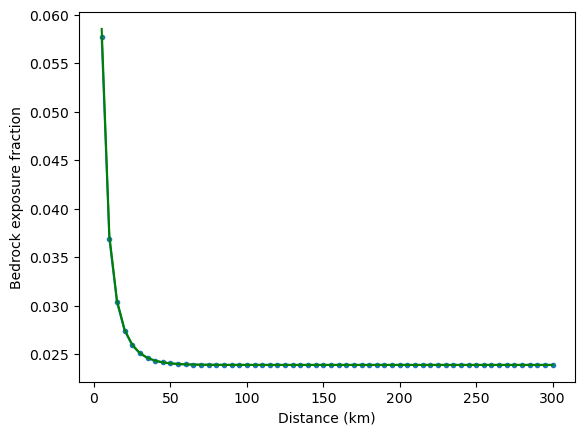

In [82]:
plt.plot(x[:-1] / 1000., phisim[:-1], '.-')
num = U * (1.0 + eps)**(5. / 3.) * (thetac * R * D)**(5. / 3.)
denom = I * kp * eps**1.5 * taucr**1.5 * mann * (r / spy) * x * Ssim**(7. / 6.) 
phiprd3 = np.divide(num, denom, where=(denom > 0.0))
plt.plot(x[:-1] / 1000., phiprd3[:-1], 'g')
plt.xlabel("Distance (km)")
plt.ylabel("Bedrock exposure fraction")

**4. Sediment flux**

Check that:
$$
Q_s = I w k_t \epsilon^{3/2} \tau_c^{3/2} (1 - \phi)$$



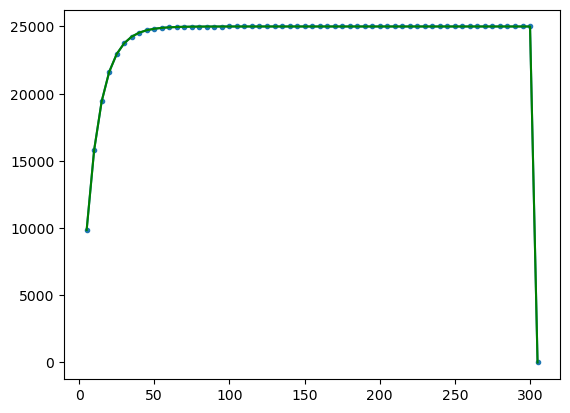

In [83]:
Qssim = modelsfnt.grid.at_node["bedload_sediment__volume_outflux"][midrow]
plt.plot(x / 1000., Qssim, '.-')
Qsprd = I * wsim * kqy * eps**1.5 * tauc**1.5 * (1.0 - phisim)
plt.plot(x / 1000., Qsprd, 'g')

Check that:
$$
Q_s = \frac{n I k_t \epsilon^{3/2} \tau_c^{3/2} Q S^{7/6} (1 - \phi)}{[(1+\epsilon) \theta_c R D]^{5/3}}
$$


Text(0, 0.5, 'Sediment flux (m3/y)')

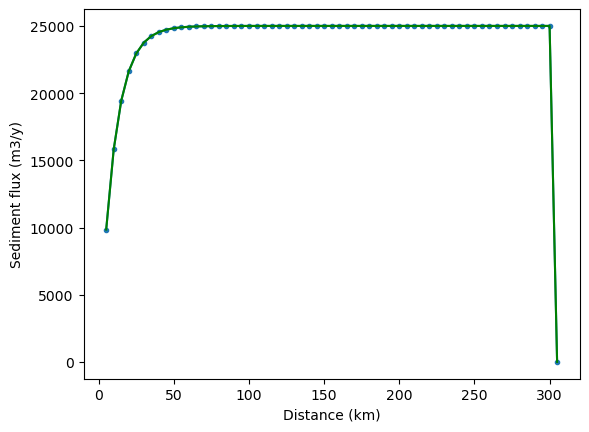

In [84]:
Qsimy = modelsfnt.grid.at_node["surface_water__discharge"][midrow]
Qsims = Qsimy / spy
Ssim = modelsfnt.grid.at_node["topographic__steepest_slope"][midrow]
plt.plot(x / 1000., Qssim, '.-')
w = mann * Qsims * Ssim**(7. / 6.) / ((1.0 + eps) * thetac * R * D)**(5. / 3.)
Qsprd = I * w * kqy * eps**1.5 * tauc**1.5 * (1.0 - phisim)
plt.plot(x / 1000., Qsprd, 'g')
plt.xlabel("Distance (km)")
plt.ylabel("Sediment flux (m3/y)")

**5. Slope**

Check that:
$$
S^{7/6} (1 - \phi) = \frac{U\gamma \Delta x [(1+\epsilon) \theta_c R D]^{5/3} (1 - e^{-\beta x})}{\beta n I k_t \epsilon^{3/2} \tau_c^{3/2} Q } 
$$

Text(0, 0.5, 'S^{7/6} (1 - \\phi)')

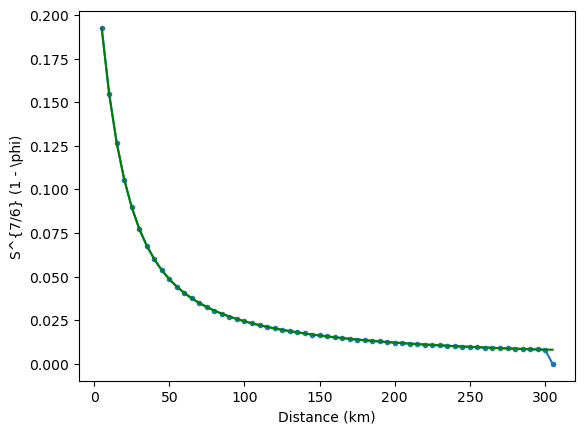

In [85]:
num = U * gamma * dx * ((1 + eps) * thetac * R * D)**(5./3.) * (1. - np.exp(-beta * x)) * spy
denom = beta * mann * I * kqy * eps**1.5 * tauc**1.5 * Qsimy
Sphiprd = num / denom
plt.plot(x / 1000., Ssim**(7. / 6.) * (1.0 - phisim), '.-')
plt.plot(x / 1000., Sphiprd, 'g')
plt.xlabel("Distance (km)")
plt.ylabel(r"S^{7/6} (1 - \phi)")

Check that:
$$
S = \left( \frac{U \left[ (1 + \epsilon) \theta_c R D\right]^{5/3}}{I n \epsilon^{3/2} \tau_c^{3/2}rx} 
\left[ \frac{\gamma (1 - e^{-\beta x})}{\beta k_t} + \frac{1}{k_p} \right] \right)^{6/7}
$$


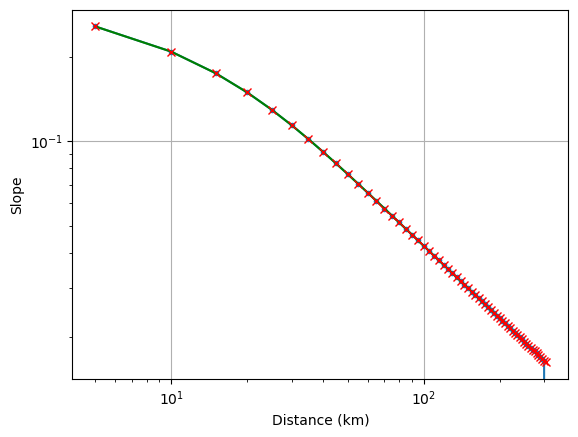

In [86]:
outern = U * ((1 + eps) * thetac * R * D)**(5. / 3.) * spy
outerd = I * mann * (eps * tauc)**1.5 * ry * x
num = gamma * (1.0 - np.exp(-beta * x))
denom = beta * kqy
Sprd = ((outern / outerd) * (num / denom + 1.0 / kp))**(6. / 7.)
Sprdfn = slope_nt(x, beta, D, gamma, I, ry, U)
plt.loglog(x / 1000., Ssim, '.-')
plt.loglog(x / 1000., Sprd, 'g')
plt.loglog(x / 1000., Sprdfn, 'rx')
plt.xlabel("Distance (km)")
plt.ylabel("Slope")
plt.grid(True)

Text(0, 0.5, 'Elevation (m)')

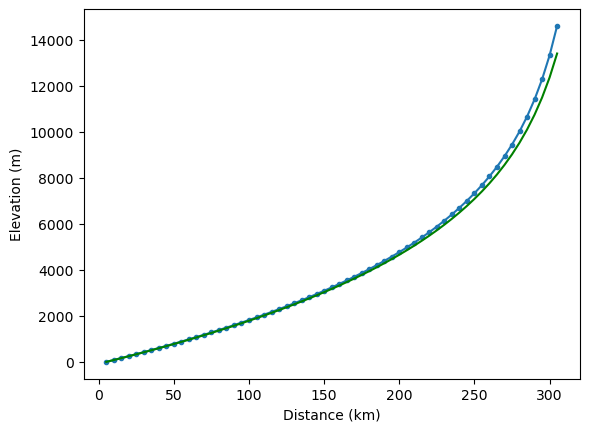

In [87]:
zsim = modelsfnt.grid.at_node["topographic__elevation"][midrow]
Sprdfn = slope_nt(x, beta, D, gamma, I, ry, U)
Sprdfnp = np.flip(Sprdfn)
zprd = np.zeros(len(x))
zprd[1:] = np.cumsum(Sprdfnp[:-1] * dx)
plt.plot(x / 1000., np.flip(zsim), '.-')
plt.plot(x / 1000., zprd, 'g')
plt.xlabel("Distance (km)")
plt.ylabel("Elevation (m)")